# 03 · Non-Orthogonal Propagation (Oblique B Field)

When the magnetic field is **not** parallel or perpendicular to the light
propagation axis, the eigenmodes of the medium are *not* orthogonal.  The
correct treatment requires a biorthogonal decomposition of the electric field.

ElecSus v4 implements this via `use_non_orthogonal=True`
(Briscoe et al., *Opt. Express* **33**, 32099, 2025), which is the default.
`use_non_orthogonal=False` gives ElecSus 3's orthogonal ("standard")
decomposition, kept for compatibility: it is exact only in Faraday and Voigt
geometry. This notebook shows when the difference matters.

`Btheta` and `Bphi` are in radians; the angles below are given in degrees and
converted with `np.radians`.


In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from elecsus import elecsus_methods as em

from elecsus.libs.plot_style import apply_style, DURHAM_CYCLE
from elecsus.libs.plot_style import d_purple, d_blue, d_red, d_yellow, d_grey

apply_style()
import warnings
# calculate() returns complex arrays; for real-valued outputs (transmission,
# Stokes parameters) the imaginary part is ~0. Silence the cast-to-real warning
# when plotting - take .real explicitly if you need the numeric values.
warnings.filterwarnings('ignore', message='Casting complex values')
det = np.linspace(-10_000, 10_000, 1000)  # MHz


## Faraday (θ = 0°) and Voigt (θ = 90°) geometries

At the two special geometries the eigenmodes are exactly orthogonal:
- **Faraday** (B ∥ k): circular σ⁺, σ⁻
- **Voigt** (B ⊥ k): linear π, σ

Both methods agree here; the difference only appears at oblique angles.

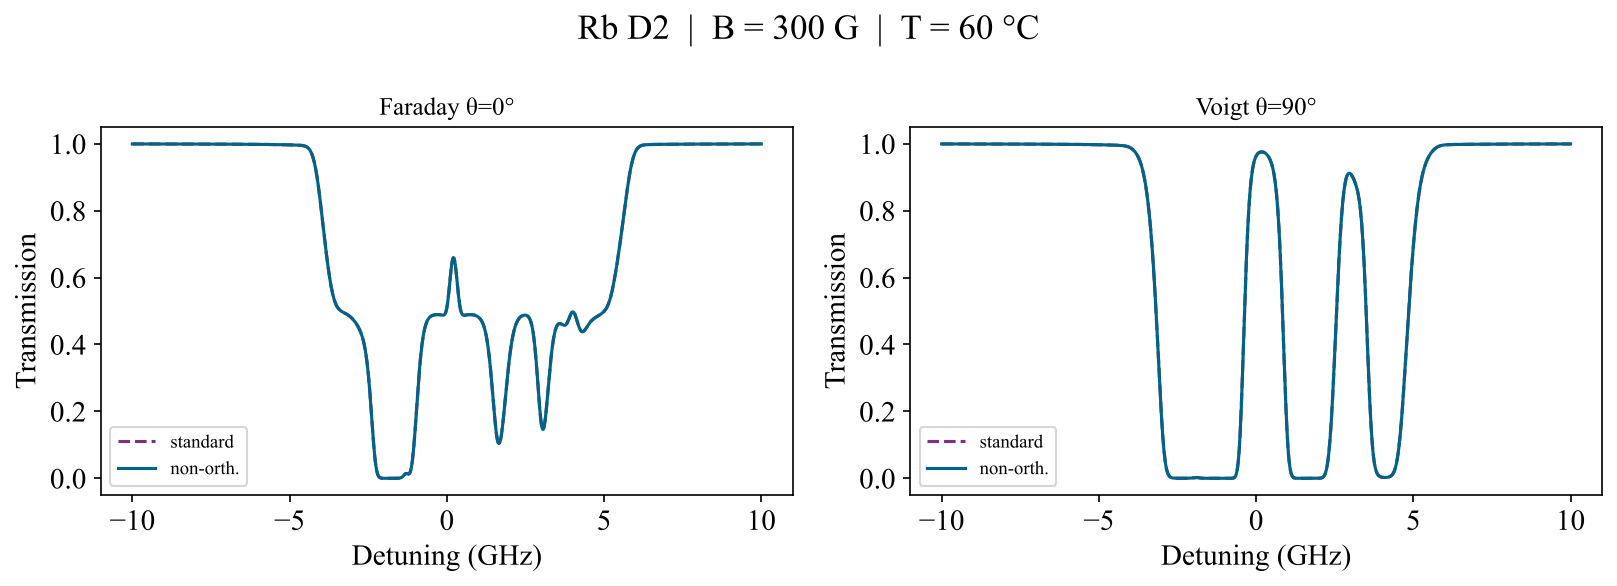

In [2]:
p_base = {'Elem':'Rb','Dline':'D2','T':60.,'lcell':75e-3,'Bfield':300}

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (theta, label) in zip(axes, [(0,'Faraday θ=0°'),(90,'Voigt θ=90°')]):
    for no, ls in [(False,'--'),(True,'-')]:
        p = {**p_base, 'Btheta':np.radians(theta), 'use_non_orthogonal':no}
        [S0] = em.calculate(det, [1,0,0], p, outputs=['S0'])
        ax.plot(det/1e3, S0, ls=ls,
                label='non-orth.' if no else 'standard')
    ax.set(xlabel='Detuning (GHz)', ylabel='Transmission', title=label)
    ax.legend(fontsize=9)
fig.suptitle('Rb D2  |  B = 300 G  |  T = 60 °C')
plt.tight_layout()


## Oblique geometry — where the correction matters

At intermediate angles the standard (orthogonal) decomposition gives
incorrect results: this is why the non-orthogonal solver is the default.  The non-orthogonal solver is based on the full
characteristic-matrix approach of Briscoe et al. 2025.

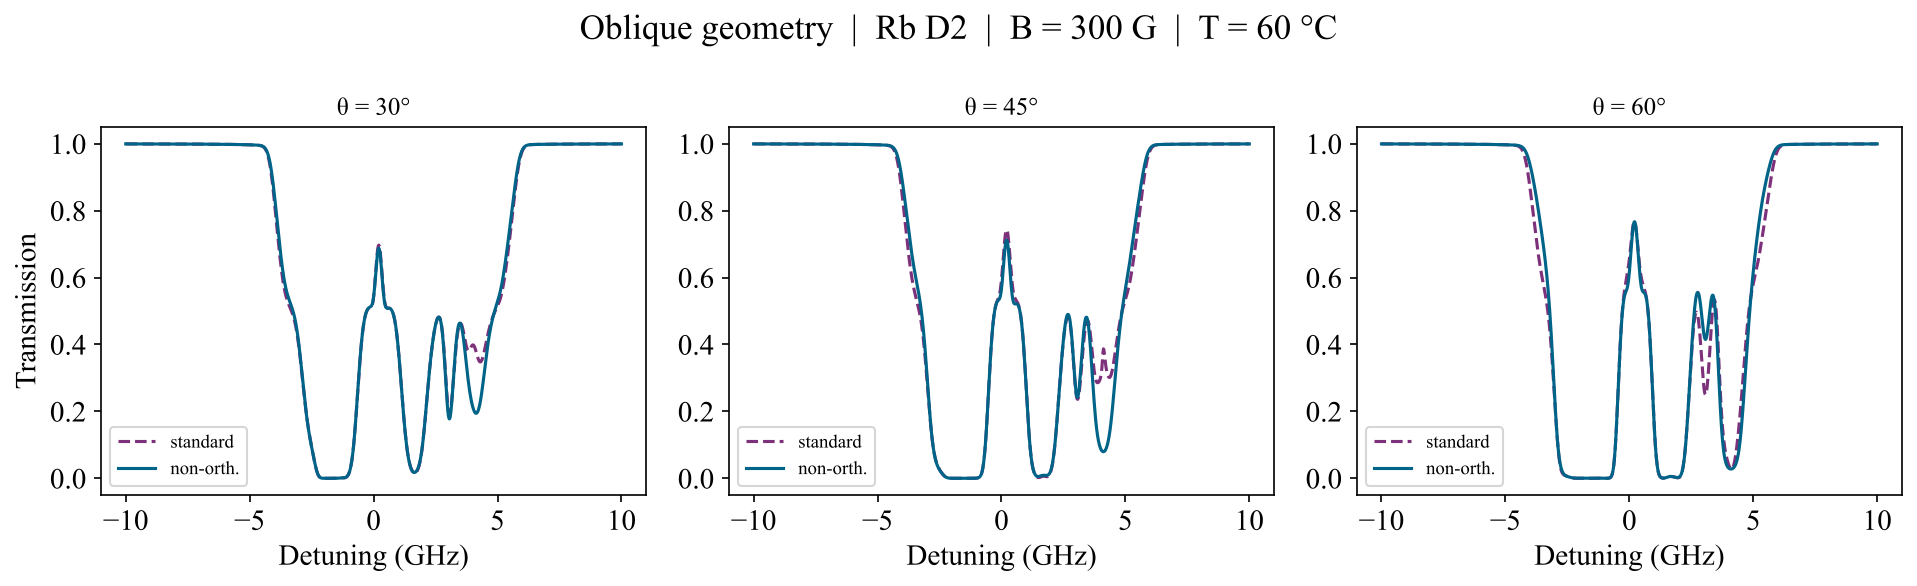

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, theta in zip(axes, [30, 45, 60]):
    for no, (ls, lbl) in [(False,('--','standard')),(True,('-','non-orth.'))]:
        p = {**p_base, 'Btheta':np.radians(theta), 'use_non_orthogonal':no}
        [S0] = em.calculate(det, [1,0,0], p, outputs=['S0'])
        ax.plot(det/1e3, S0, ls=ls, label=lbl)
    ax.set(xlabel='Detuning (GHz)', title=f'θ = {theta}°')
    ax.legend(fontsize=9)
axes[0].set_ylabel('Transmission')
fig.suptitle('Oblique geometry  |  Rb D2  |  B = 300 G  |  T = 60 °C')
plt.tight_layout()


## Cell-window Fresnel correction

`n_window` sets the refractive index of the cell windows (1.51 for
borosilicate glass; the default, `None`, models a cell without windows).
It needs the non-orthogonal solver.  At oblique angles the per-eigenmode Fresnel correction
modifies the effective intensity each mode sees at the entrance and exit faces.
`n_window=None` disables the correction (a windowless cell).

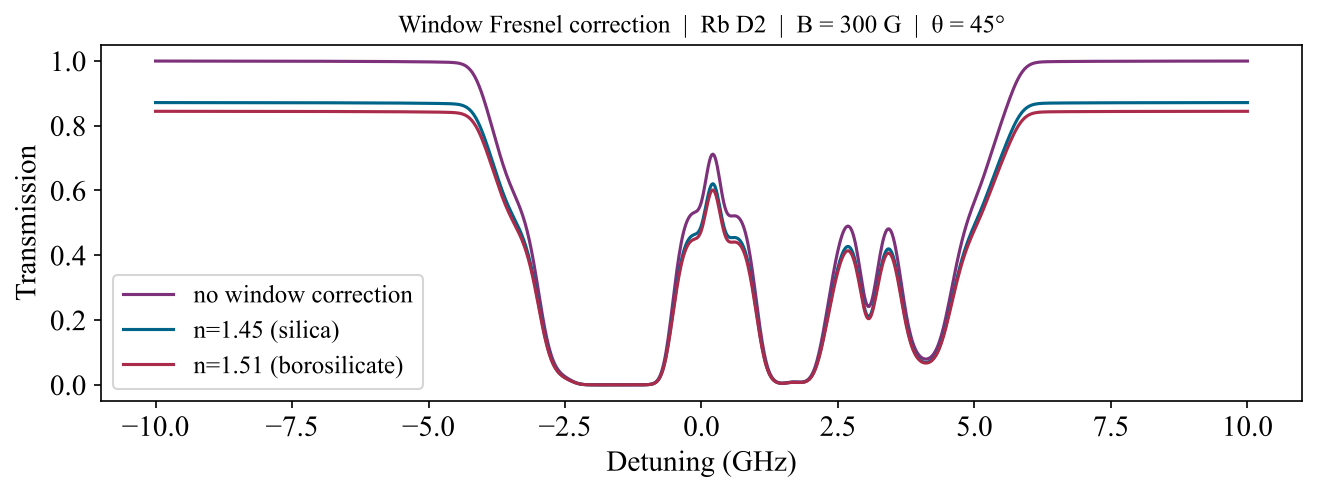

In [4]:
theta = 45
fig, ax = plt.subplots(figsize=(9, 3.5))
for n_win, lbl in [(None,'no window correction'),(1.45,'n=1.45 (silica)'),(1.51,'n=1.51 (borosilicate)')]:
    p = {**p_base, 'Btheta':np.radians(theta), 'use_non_orthogonal':True, 'n_window':n_win}
    [S0] = em.calculate(det, [1,0,0], p, outputs=['S0'])
    ax.plot(det/1e3, S0, label=lbl)
ax.set(xlabel='Detuning (GHz)', ylabel='Transmission',
       title=f'Window Fresnel correction  |  Rb D2  |  B = 300 G  |  θ = {theta}°')
ax.legend()
plt.tight_layout()


## Angular sweep — maximum deviation from standard model

Compute the peak absolute difference |S0_nonorth − S0_standard| across all
detuning points as a function of θ.  The deviation is zero at 0° and 90°,
where the eigenmodes are orthogonal, and large in between: here up to ~0.5
in transmission.

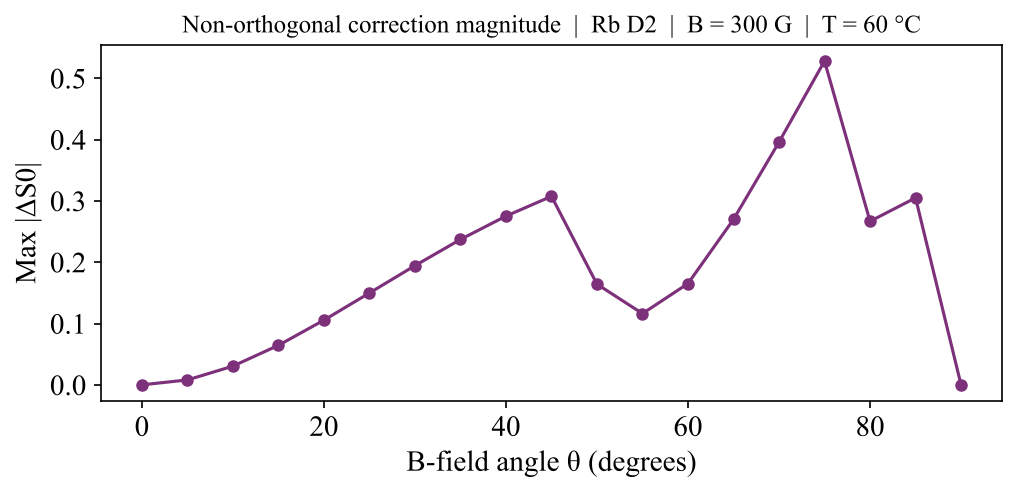

In [5]:
thetas = np.linspace(0, 90, 19)
max_diff = []
for theta in thetas:
    p_std = {**p_base, 'Btheta':np.radians(theta), 'use_non_orthogonal':False}
    p_no  = {**p_base, 'Btheta':np.radians(theta), 'use_non_orthogonal':True}
    [S0_std] = em.calculate(det, [1,0,0], p_std, outputs=['S0'])
    [S0_no]  = em.calculate(det, [1,0,0], p_no,  outputs=['S0'])
    max_diff.append(np.max(np.abs(S0_no - S0_std)))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(thetas, max_diff, 'o-')
ax.set(xlabel='B-field angle θ (degrees)',
       ylabel='Max |ΔS0|',
       title='Non-orthogonal correction magnitude  |  Rb D2  |  B = 300 G  |  T = 60 °C')
plt.tight_layout()
